# 100｜量化蒸馏与压缩

CPU离线实验。先读lecture.md和lab.md，从本讲目录按序运行；重跑覆盖本目录outputs。

In [1]:
from pathlib import Path
import json, numpy as np
import experiment as e
print("Ready: CPU experiment")

Ready: CPU experiment


## 运行完整协议

不跳过失败配置，不将墙钟时间视为固定硬件保证。

In [2]:
e.main()

{
  "quality": [
    {
      "seed": 11,
      "method": "float32",
      "group": "all",
      "n": 1200,
      "accuracy": 0.9733333333333334,
      "raw_parameter_payload_bytes": 648,
      "inference_kernel": "float32 matmul; optional fake activation quantization",
      "activation_clip_limit": null
    },
    {
      "seed": 11,
      "method": "float32",
      "group": "common",
      "n": 941,
      "accuracy": 0.9904357066950054,
      "raw_parameter_payload_bytes": 648,
      "inference_kernel": "float32 matmul; optional fake activation quantization",
      "activation_clip_limit": null
    },
    {
      "seed": 11,
      "method": "float32",
      "group": "tail",
      "n": 259,
      "accuracy": 0.9111969111969112,
      "raw_parameter_payload_bytes": 648,
      "inference_kernel": "float32 matmul; optional fake activation quantization",
      "activation_clip_limit": null
    },
    {
      "seed": 11,
      "method": "w8",
      "group": "all",
      "n": 1200,
      "a

In [3]:
metrics = json.loads(Path("outputs/metrics.json").read_text())
print("Result fields:", list(metrics))

Result fields: ['protocol', 'quality', 'timings', 'calibration', 'configs', 'training_steps', 'seeds', 'test_examples']


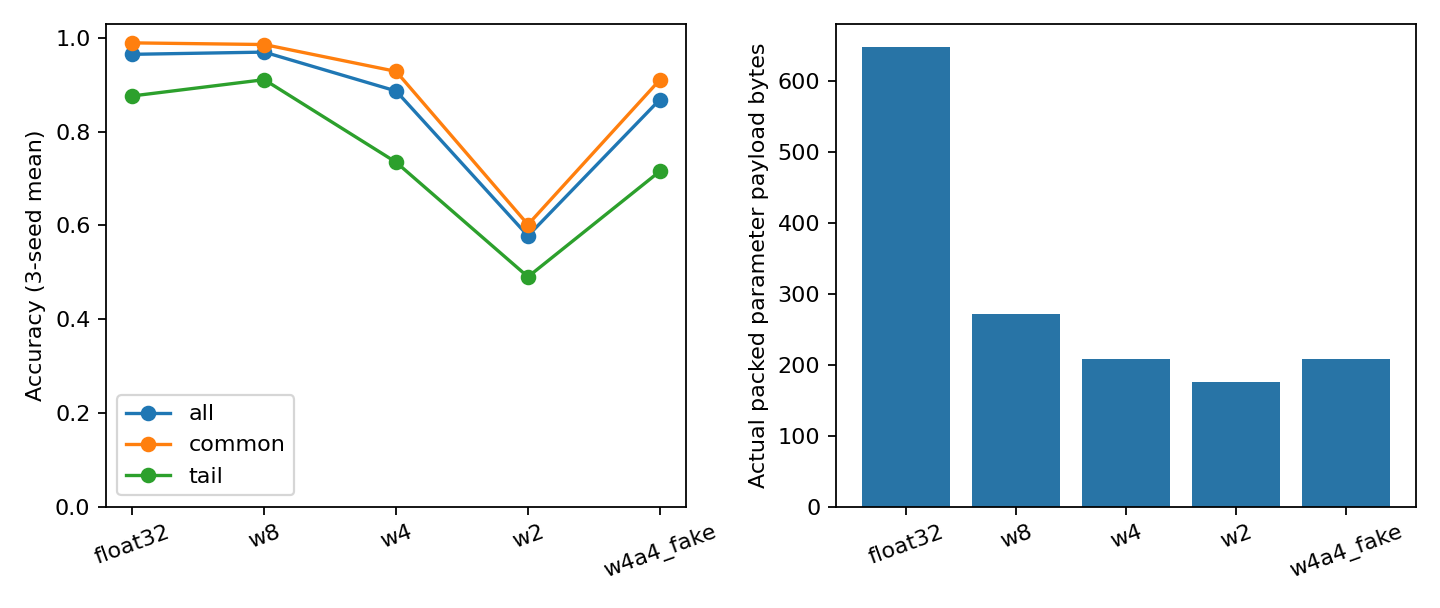

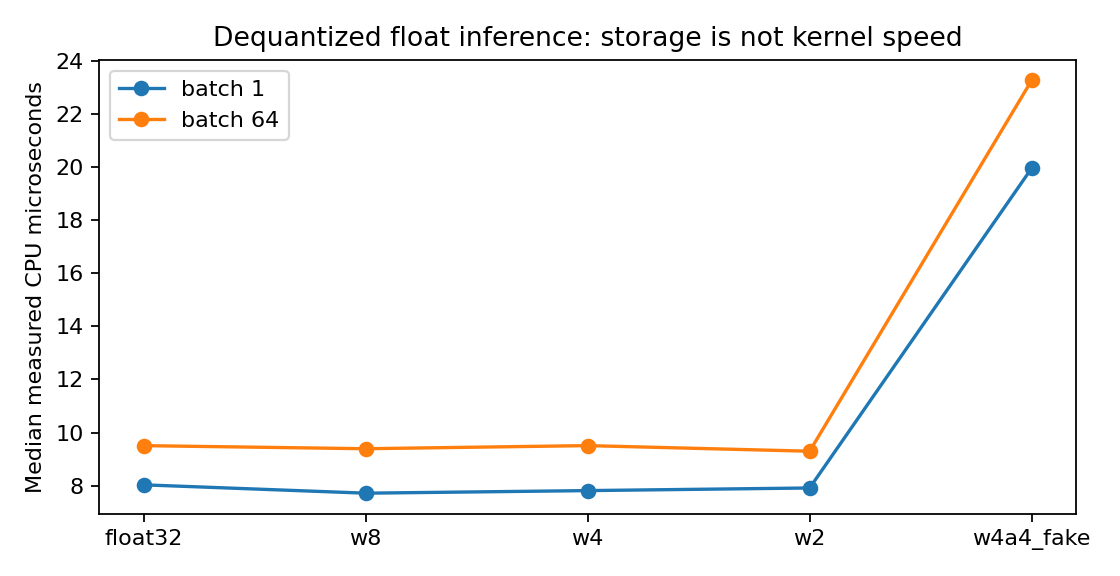

In [4]:
from IPython.display import display, Image
for path in sorted(Path("figures").glob("*.png")):
    display(Image(filename=str(path)))

## 独立断言

此处运行tests.py中的全部测试；失败必须先诊断，不能删除断言。

In [5]:
import unittest, tests
result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromModule(tests))
assert result.wasSuccessful()

test_pack_roundtrip (tests.Tests.test_pack_roundtrip) ... 

ok


test_protocol (tests.Tests.test_protocol) ... 

ok


test_quality_recompute (tests.Tests.test_quality_recompute) ... 

...

test_rounding_bound (tests.Tests.test_rounding_bound) ... 

ok


test_zero_weight (tests.Tests.test_zero_weight) ... 

ok


----------------------------------------------------------------------
Ran 6 tests in 0.026s

OK


In [6]:
print("解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？")

解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？
